# Этап 2. Проверка конвейера на реальных данных ClinVar

**Проект:** «Прогнозирование патогенности генетических мутаций с использованием математических признаков и машинного обучения»
**Автор:** Абдукадырова Балауса, 10 «Д»

В основной работе модель проверялась на синтетических данных. Здесь тот же конвейер
(признаки → стандартизация и one-hot → 3 модели → вероятность → метрики → ошибки)
запускается на **настоящих** вариантах из открытой базы ClinVar.

**Как запустить:** открыть файл в Google Colab (colab.research.google.com → «Загрузить блокнот»)
и выбрать «Среда выполнения → Выполнить всё». Нужен интернет, расчёт занимает 3–8 минут.

**Данные (публичные, без персональной информации):**
* ClinVar, релиз от 23.09.2019, сборка генома GRCh38 — копия в открытом хранилище gnomAD (Google Cloud).
  Релиз зафиксирован, чтобы результат можно было повторить точно.
* Референсный геном человека hg38 (Broad Institute) — из него берём 25 нуклеотидов слева и справа от варианта.

In [1]:
import gzip, math, os, urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42          # фиксируем случайность, чтобы результат повторялся
N_SAMPLE = 4000    # столько же объектов, сколько в синтетическом эксперименте
WINDOW = 25        # окно для энтропии и GC: 25 + вариант + 25 нуклеотидов

CLINVAR_URL = "https://storage.googleapis.com/gcp-public-data--gnomad/resources/grch38/clinvar_20190923.vcf.gz"
FASTA_URL = "https://storage.googleapis.com/gcp-public-data--broad-references/hg38/v0/Homo_sapiens_assembly38.fasta"

## Шаг 1. Скачиваем ClinVar (21 МБ) и индекс генома
Сам геном (3 ГБ) целиком не скачиваем: по индексу `.fai` можно запросить только нужные 51 букву.

In [2]:
for url, name in [(CLINVAR_URL, "clinvar.vcf.gz"), (FASTA_URL + ".fai", "hg38.fai")]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)
print({n: os.path.getsize(n) for n in ["clinvar.vcf.gz", "hg38.fai"]})

{'clinvar.vcf.gz': 21348681, 'hg38.fai': 160928}


## Шаг 2. Отбираем варианты с надёжной разметкой
* **Класс 1 (патогенный):** Pathogenic, Likely_pathogenic. **Класс 0 (доброкачественный):** Benign, Likely_benign.
* Варианты неопределённого значения и конфликтующие оценки исключаем.
* Оставляем только записи, где у оценки есть критерии (review status ≥ 1 звезды).

Признаки, которые берём прямо из ClinVar:
* **AF** — частота аллеля (максимум из ExAC, ESP, 1000 Genomes). Если вариант в этих базах не найден,
  считаем его очень редким и ставим флаг `AF_known = 0`. Для модели используем log10(AF + 0,00001).
* **M** — молекулярное последствие (missense, nonsense, frameshift…; если их несколько — самое тяжёлое).
* **VT** — тип варианта, **L** — длина, **T** — переход или трансверсия (только для однобуквенных замен).

In [3]:
PATHOGENIC = {"Pathogenic", "Likely_pathogenic", "Pathogenic/Likely_pathogenic"}
BENIGN = {"Benign", "Likely_benign", "Benign/Likely_benign"}
GOOD_REVIEW = {"criteria_provided,_single_submitter", "criteria_provided,_multiple_submitters,_no_conflicts",
               "reviewed_by_expert_panel", "practice_guideline"}
SEVERITY = ["nonsense", "frameshift_variant", "splice_donor_variant", "splice_acceptor_variant",
            "initiatior_codon_variant", "stop_lost", "inframe_deletion", "inframe_insertion", "inframe_indel",
            "missense_variant", "synonymous_variant", "5_prime_UTR_variant", "3_prime_UTR_variant",
            "intron_variant", "non-coding_transcript_variant"]
TRANSITIONS = {("A", "G"), ("G", "A"), ("C", "T"), ("T", "C")}

rows, n_total = [], 0
with gzip.open("clinvar.vcf.gz", "rt") as f:
    for line in f:
        if line.startswith("#"):
            continue
        n_total += 1
        chrom, pos, vid, ref, alt, _, _, info = line.rstrip("\n").split("\t")[:8]
        d = dict(kv.split("=", 1) for kv in info.split(";") if "=" in kv)
        sig = d.get("CLNSIG")
        if sig in PATHOGENIC:
            y = 1
        elif sig in BENIGN:
            y = 0
        else:
            continue
        if d.get("CLNREVSTAT") not in GOOD_REVIEW or "MC" not in d or alt == ".":
            continue
        mcs = {m.split("|")[1] for m in d["MC"].split(",")}
        afs = [float(d[k]) for k in ("AF_EXAC", "AF_ESP", "AF_TGP") if k in d]
        snv = len(ref) == 1 and len(alt) == 1
        rows.append(dict(chrom=chrom, pos=int(pos), id=vid, ref=ref, alt=alt, y=y,
                         gene=d.get("GENEINFO", "?").split(":")[0],
                         AF=max(afs) if afs else np.nan,
                         M=next((s for s in SEVERITY if s in mcs), "other"),
                         VT=d.get("CLNVC", "other"),
                         L=max(1, abs(len(alt) - len(ref))),
                         T=("transition" if (ref, alt) in TRANSITIONS else "transversion") if snv else "not_snv"))

df = pd.DataFrame(rows)
df["AF_known"] = df["AF"].notna().astype(int)
df["logAF"] = np.log10(df["AF"].fillna(0) + 1e-5)
print("Всего записей в ClinVar:", n_total)
print("После фильтра:", len(df), "| патогенных:", df.y.sum(), "| доброкачественных:", (df.y == 0).sum())

Всего записей в ClinVar: 500570
После фильтра: 208363 | патогенных: 69441 | доброкачественных: 138922


## Шаг 3. Случайная выборка 4000 и контекст последовательности
Выборка стратифицированная: доля классов та же, что во всём отфильтрованном ClinVar.

**Энтропия Шеннона** окна: $H = -\sum p_i \log_2 p_i$, где $p_i$ — доля нуклеотида A, C, G или T.
Проверка формулы на простых примерах:

In [4]:
def entropy(seq):
    seq = [c for c in seq.upper() if c in "ACGT"]
    n = len(seq)
    return -sum((k / n) * math.log2(k / n) for k in Counter(seq).values()) + 0.0

for s in ["AAAAAAAA", "AAAAAAAC", "AACCAACC", "ACGTACGT"]:
    print(s, "H =", round(entropy(s), 3), "бит")

AAAAAAAA H = 0.0 бит
AAAAAAAC H = 0.544 бит
AACCAACC H = 1.0 бит
ACGTACGT H = 2.0 бит


In [5]:
sample, _ = train_test_split(df, train_size=N_SAMPLE, stratify=df.y, random_state=SEED)
sample = sample.reset_index(drop=True)

fai = {}
for line in open("hg38.fai"):
    name, length, offset, lb, lbytes = line.split("\t")[:5]
    fai[name] = tuple(map(int, (length, offset, lb, lbytes)))

def fetch(chrom, start0, end0):
    # читаем из файла генома только байты нужного участка (HTTP Range)
    length, offset, lb, lbytes = fai["chrM" if chrom == "MT" else "chr" + chrom]
    start0, end0 = max(0, start0), min(length, end0)
    b0 = offset + (start0 // lb) * lbytes + start0 % lb
    b1 = offset + ((end0 - 1) // lb) * lbytes + (end0 - 1) % lb
    req = urllib.request.Request(FASTA_URL, headers={"Range": f"bytes={b0}-{b1}"})
    for attempt in range(4):
        try:
            return urllib.request.urlopen(req, timeout=30).read().decode().replace("\n", "").upper()
        except Exception:
            if attempt == 3:
                raise

def context(r):
    return fetch(r.chrom, r.pos - 1 - WINDOW, r.pos - 1 + len(r.ref) + WINDOW)

with ThreadPoolExecutor(16) as ex:
    seqs = list(ex.map(context, sample.itertuples()))

# контроль качества: буква из генома должна совпасть с референсной буквой в ClinVar
match = np.mean([s[WINDOW:WINDOW + len(r.ref)] == r.ref.upper() for s, r in zip(seqs, sample.itertuples())])
print("Совпадение референсного аллеля с геномом:", round(match, 4))

sample["H"] = [entropy(s) for s in seqs]
sample["G"] = [sum(c in "GC" for c in s) / max(1, sum(c in "ACGT" for c in s)) for s in seqs]
print("Патогенных:", sample.y.sum(), "| доброкачественных:", (sample.y == 0).sum(), "| генов:", sample.gene.nunique())
sample.groupby("y")[["AF_known", "H", "G", "L"]].mean().round(3)

Совпадение референсного аллеля с геномом: 1.0
Патогенных: 1333 | доброкачественных: 2667 | генов: 1399


,AF_known,H,G,L
y,,,,
0,0.629,1.883,0.509,1.138
1,0.116,1.910,0.497,4.962


## Шаг 4. Тот же конвейер, что в синтетическом эксперименте
Деление 80/20 со стратификацией, стандартизация числовых признаков и one-hot для категорий внутри Pipeline
(μ и σ считаются только по обучающей части), три модели, порог 0,5.

In [6]:
NUM = ["logAF", "AF_known", "L", "H", "G"]
CAT = ["M", "VT", "T"]

def make(model, num=NUM, cat=CAT):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre), ("clf", model)])

MODELS = {
    "Логистическая регрессия": lambda: LogisticRegression(max_iter=2000),
    "Случайный лес": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "Градиентный бустинг": lambda: GradientBoostingClassifier(random_state=SEED),
}
X, y = sample[NUM + CAT], sample.y.values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

table, probs, fitted = [], {}, {}
for name, mk in MODELS.items():
    m = make(mk()).fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    yh = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, yh).ravel()
    table.append(dict(Модель=name, Accuracy=accuracy_score(yte, yh), Precision=precision_score(yte, yh),
                      Recall=recall_score(yte, yh), F1=f1_score(yte, yh), ROC_AUC=roc_auc_score(yte, p),
                      TN=tn, FP=fp, FN=fn, TP=tp))
    probs[name], fitted[name] = p, m
pd.DataFrame(table).round(3)

,Модель,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,Логистическая регрессия,0.970,0.955,0.955,0.955,0.988,521,12,12,255
1,Случайный лес,0.969,0.965,0.940,0.953,0.985,524,9,16,251
2,Градиентный бустинг,0.970,0.962,0.948,0.955,0.988,523,10,14,253


### Ручная проверка по матрице ошибок (градиентный бустинг)

In [7]:
r = table[2]
print(f"Accuracy  = (TN+TP)/n   = ({r['TN']}+{r['TP']})/{len(yte)} = {(r['TN'] + r['TP']) / len(yte):.3f}")
print(f"Precision = TP/(TP+FP)  = {r['TP']}/({r['TP']}+{r['FP']}) = {r['TP'] / (r['TP'] + r['FP']):.3f}")
print(f"Recall    = TP/(TP+FN)  = {r['TP']}/({r['TP']}+{r['FN']}) = {r['TP'] / (r['TP'] + r['FN']):.3f}")
print("Модель «всегда доброкачественный» дала бы Accuracy =", round((yte == 0).mean(), 3))

Accuracy  = (TN+TP)/n   = (523+253)/800 = 0.970
Precision = TP/(TP+FP)  = 253/(253+10) = 0.962
Recall    = TP/(TP+FN)  = 253/(253+14) = 0.948
Модель «всегда доброкачественный» дала бы Accuracy = 0.666


### Разбор одного настоящего варианта (пример для защиты)

In [8]:
test = sample.loc[Xte.index].assign(p=probs["Логистическая регрессия"])

def explain(ex):
    print(f"Ген {ex['gene']}, хромосома {ex['chrom']}, позиция {ex['pos']}, замена {ex['ref']}>{ex['alt']}, ClinVar ID {ex['id']}")
    print(f"  последствие: {ex['M']}; частота аллеля: {'не найден в базах' if not ex['AF_known'] else ex['AF']}; "
          f"H = {ex['H']:.3f} бит; GC = {ex['G']:.3f}; {ex['T']}")
    print(f"  P(y=1|x) = {ex['p']:.3f}; решение модели при t = 0,5: {int(ex['p'] >= 0.5)}; метка ClinVar: {ex['y']}")

print("Верный ответ:")
explain(test[(test.M == "nonsense") & (test.y == 1)].iloc[0])
print("Ошибка модели (пропущенный патогенный, FN):")
explain(test[(test.M == "missense_variant") & (test.y == 1) & (test.p < 0.5)].iloc[0])

lr = fitted["Логистическая регрессия"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
coef.sort_values().round(2)

Верный ответ:
Ген ATM, хромосома 11, позиция 108227857, замена G>T, ClinVar ID 181946
  последствие: nonsense; частота аллеля: не найден в базах; H = 1.927 бит; GC = 0.373; transversion
  P(y=1|x) = 0.990; решение модели при t = 0,5: 1; метка ClinVar: 1
Ошибка модели (пропущенный патогенный, FN):
Ген PHF3, хромосома 6, позиция 63721252, замена A>G, ClinVar ID 624249
  последствие: missense_variant; частота аллеля: 0.00022; H = 1.782 бит; GC = 0.333; transition
  P(y=1|x) = 0.182; решение модели при t = 0,5: 0; метка ClinVar: 1


cat__M_synonymous_variant              -4.62
cat__M_intron_variant                  -3.77
num__logAF                             -2.73
cat__M_3_prime_UTR_variant             -2.65
cat__M_5_prime_UTR_variant             -2.42
cat__M_inframe_insertion               -1.21
cat__M_other                           -0.86
cat__M_non-coding_transcript_variant   -0.83
cat__VT_Inversion                      -0.61
cat__VT_Microsatellite                 -0.58
cat__VT_Indel                          -0.55
cat__VT_single_nucleotide_variant      -0.22
cat__T_not_snv                         -0.16
cat__T_transition                      -0.11
cat__T_transversion                    -0.10
num__G                                  0.01
num__AF_known                           0.10
cat__M_inframe_indel                    0.19
num__L                                  0.21
cat__VT_Insertion                       0.35
cat__M_inframe_deletion                 0.35
num__H                                  0.42
cat__VT_De

## Шаг 5. Надёжность: кросс-валидация
* **5-кратная кросс-валидация:** данные 5 раз делятся на обучение и тест по-разному, считаем среднее ± отклонение.
* **Проверка на новых генах (GroupKFold):** варианты одного гена всегда целиком попадают либо в обучение, либо в тест —
  так модель не может «запомнить» ген.

In [9]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rel = []
for name, mk in MODELS.items():
    a = cross_val_score(make(mk()), X, y, cv=cv, scoring="roc_auc")
    g = cross_val_score(make(mk()), X, y, cv=GroupKFold(5), groups=sample.gene, scoring="roc_auc")
    rel.append(dict(Модель=name, CV_AUC=f"{a.mean():.3f} ± {a.std():.3f}", Новые_гены_AUC=f"{g.mean():.3f} ± {g.std():.3f}"))
pd.DataFrame(rel)

,Модель,CV_AUC,Новые_гены_AUC
0,Логистическая регрессия,0.990 ± 0.003,0.990 ± 0.005
1,Случайный лес,0.988 ± 0.004,0.988 ± 0.004
2,Градиентный бустинг,0.990 ± 0.003,0.990 ± 0.004


## Шаг 6. Проверка гипотезы: один признак против всех вместе
Для каждого признака отдельно обучаем логистическую регрессию и считаем ROC-AUC (5-кратная CV).
Потом проверяем, нужна ли энтропия: убираем её и смотрим, изменится ли качество.

In [10]:
LABEL = {"logAF": "Частота аллеля", "L": "Длина", "H": "Энтропия H", "G": "GC-доля",
         "M": "Последствие", "VT": "Тип варианта", "T": "Переход/трансверсия"}
single = {}
for feat in ["logAF", "L", "H", "G", "M", "VT", "T"]:
    num = ["logAF", "AF_known"] if feat == "logAF" else ([feat] if feat in NUM else [])
    cat = [feat] if feat in CAT else []
    s = cross_val_score(make(LogisticRegression(max_iter=2000), num, cat), sample[num + cat], y, cv=cv, scoring="roc_auc")
    single[LABEL[feat]] = s
abl = {}
for label, num, cat in [("Все признаки", NUM, CAT), ("Без энтропии H", [c for c in NUM if c != "H"], CAT),
                        ("Без H и GC", ["logAF", "AF_known", "L"], CAT), ("Только H и GC", ["H", "G"], [])]:
    abl[label] = cross_val_score(make(GradientBoostingClassifier(random_state=SEED), num, cat),
                                 sample[num + cat], y, cv=cv, scoring="roc_auc")
show = lambda d: pd.DataFrame({k: [f"{v.mean():.3f} ± {v.std():.3f}"] for k, v in d.items()}).T.rename(columns={0: "ROC-AUC"})
display(show(single)); display(show(abl))

,ROC-AUC
Частота аллеля,0.782 ± 0.018
Длина,0.568 ± 0.016
Энтропия H,0.579 ± 0.019
GC-доля,0.529 ± 0.014
Последствие,0.972 ± 0.004
Тип варианта,0.673 ± 0.018
Переход/трансверсия,0.702 ± 0.021


,ROC-AUC
Все признаки,0.990 ± 0.003
Без энтропии H,0.990 ± 0.002
Без H и GC,0.990 ± 0.002
Только H и GC,0.637 ± 0.009


### Только миссенс-варианты
Самый трудный случай: у всех вариантов одинаковое последствие (заменена одна аминокислота),
поэтому модель не может опереться на «тяжесть» мутации.

In [11]:
mis = sample[sample.M == "missense_variant"]
print("Миссенс-вариантов:", len(mis), "| из них патогенных:", mis.y.sum())
for label, cols in [("Только частота", ["logAF", "AF_known"]), ("Только H и GC", ["H", "G"]),
                    ("Частота + H + GC + тип замены", ["logAF", "AF_known", "H", "G", "T"])]:
    num, cat = [c for c in cols if c != "T"], [c for c in cols if c == "T"]
    s = cross_val_score(make(GradientBoostingClassifier(random_state=SEED), num, cat), mis[cols], mis.y, cv=cv, scoring="roc_auc")
    print(f"{label}: ROC-AUC = {s.mean():.3f} ± {s.std():.3f}")

Миссенс-вариантов: 716 | из них патогенных: 332


Только частота: ROC-AUC = 0.895 ± 0.020


Только H и GC: ROC-AUC = 0.555 ± 0.061


Частота + H + GC + тип замены: ROC-AUC = 0.897 ± 0.026


## Шаг 7. Выбор порога: компромисс между ложными тревогами и пропусками

In [12]:
p = probs["Градиентный бустинг"]
rows_t = []
for t in (0.3, 0.5, 0.7):
    yh = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, yh).ravel()
    rows_t.append(dict(Порог=t, Precision=round(precision_score(yte, yh), 3), Recall=round(recall_score(yte, yh), 3),
                       Ложные_тревоги_FP=fp, Пропуски_FN=fn))
pd.DataFrame(rows_t)

,Порог,Precision,Recall,Ложные_тревоги_FP,Пропуски_FN
0,0.3,0.938,0.970,17,8
1,0.5,0.962,0.948,10,14
2,0.7,0.965,0.929,9,19


## Шаг 7б. Пример: муковисцидоз (ген CFTR)
Муковисцидоз вызывают вредные варианты гена CFTR на 7-й хромосоме. Проверим модель на всех
отфильтрованных вариантах CFTR из ClinVar. Чтобы проверка была честной, варианты CFTR убираем из обучения:
модель видит этот ген впервые.

In [13]:
cf = df[df.gene == "CFTR"].copy()
with ThreadPoolExecutor(16) as ex:
    cf_seqs = list(ex.map(context, cf.itertuples()))
cf["H"] = [entropy(s) for s in cf_seqs]
cf["G"] = [sum(c in "GC" for c in s) / max(1, sum(c in "ACGT" for c in s)) for s in cf_seqs]

train_no_cf = sample[sample.gene != "CFTR"]
m = make(GradientBoostingClassifier(random_state=SEED)).fit(train_no_cf[NUM + CAT], train_no_cf.y)
cf["p"] = m.predict_proba(cf[NUM + CAT])[:, 1]
tn, fp, fn, tp = confusion_matrix(cf.y, (cf.p >= 0.5).astype(int)).ravel()
print(f"Вариантов CFTR: {len(cf)} (патогенных {cf.y.sum()}), ROC-AUC = {roc_auc_score(cf.y, cf.p):.3f}")
print(f"Найдено патогенных: {tp} из {tp + fn}; ложных тревог: {fp} из {fp + tn}")

f508 = cf[(cf.pos == 117559590) & (cf.ref == "ATCT") & (cf.alt == "A")].iloc[0]
print(f"F508del (потеря 3 нуклеотидов и фенилаланина в позиции 508): P(y=1|x) = {f508.p:.3f}, метка ClinVar: {f508.y}")
print("Какие патогенные варианты модель пропустила (по последствию):")
print(cf[(cf.y == 1) & (cf.p < 0.5)].M.value_counts())

Вариантов CFTR: 645 (патогенных 562), ROC-AUC = 0.991
Найдено патогенных: 521 из 562; ложных тревог: 3 из 83
F508del (потеря 3 нуклеотидов и фенилаланина в позиции 508): P(y=1|x) = 0.750, метка ClinVar: 1
Какие патогенные варианты модель пропустила (по последствию):
M
intron_variant        21
missense_variant      14
synonymous_variant     4
inframe_insertion      2
Name: count, dtype: int64


## Шаг 7в. Формула из 4 признаков для ручного расчёта (как на стенде)
Чтобы модель можно было посчитать на бумаге, обучим логистическую регрессию всего на 4 признаках:
- x₁ = 1, если белок обрывается (нонсенс, сдвиг рамки, сплайсинг, потеря старт-кодона);
- x₂ = 1, если белок изменён (миссенс, вставка или потеря без сдвига рамки);
- x₃ = lg(AF + 0,00001) — редкость варианта;
- x₄ = H — энтропия Шеннона окна вокруг варианта.

Модель: z = b + w₁x₁ + w₂x₂ + w₃x₃ + w₄x₄, P = 1 / (1 + e^(−z)).

In [14]:
LOF = {"frameshift_variant", "nonsense", "splice_donor_variant", "splice_acceptor_variant", "initiatior_codon_variant"}
PROT = {"missense_variant", "inframe_deletion", "inframe_insertion", "inframe_indel"}
def four(d):
    return pd.DataFrame({"x1": d.M.isin(LOF).astype(int), "x2": d.M.isin(PROT).astype(int),
                         "x3": d.logAF, "x4": d.H})

X4 = four(sample)
cv4 = cross_val_score(LogisticRegression(max_iter=2000), X4, sample.y,
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
# веса подбираем без гена CFTR, чтобы проверка на муковисцидозе была честной
lr4 = LogisticRegression(max_iter=2000).fit(four(train_no_cf), train_no_cf.y)
b = round(lr4.intercept_[0], 1); w = [round(v, 1) for v in lr4.coef_[0]]
print(f"z = {b} + {w[0]}·x1 + {w[1]}·x2 + ({w[2]})·x3 + {w[3]}·x4")
print(f"ROC-AUC формулы (5-кратная кросс-валидация): {cv4.mean():.3f} ± {cv4.std():.3f}")

def predict(x1, x2, x3, x4):
    z = b + w[0] * x1 + w[1] * x2 + w[2] * x3 + w[3] * x4
    p = 1 / (1 + np.exp(-z))
    print(f"z = {b} + {w[0]}·{x1} + {w[1]}·{x2} + ({w[2]})·({x3}) + {w[3]}·{x4} = {z:.2f}")
    print(f"P = 1 / (1 + e^(−{z:.2f})) = {p:.3f} → {'патогенный' if p >= 0.5 else 'доброкачественный'}")

print("\nF508del:")
predict(0, 1, -5, round(f508.H, 2))

z_cf = b + (four(cf).values * w).sum(axis=1)
found = ((z_cf >= 0) & (cf.y == 1)).sum()
print(f"\nФормула на гене CFTR: найдено {found} из {cf.y.sum()} патогенных, "
      f"ложных тревог {((z_cf >= 0) & (cf.y == 0)).sum()} из {(cf.y == 0).sum()}")

z = -16.3 + 8.1·x1 + 4.7·x2 + (-1.8)·x3 + 2.2·x4
ROC-AUC формулы (5-кратная кросс-валидация): 0.989 ± 0.004

F508del:
z = -16.3 + 8.1·0 + 4.7·1 + (-1.8)·(-5) + 2.2·1.93 = 1.65
P = 1 / (1 + e^(−1.65)) = 0.838 → патогенный

Формула на гене CFTR: найдено 520 из 562 патогенных, ложных тревог 2 из 83


## Калькулятор для жюри
Эта ячейка работает сама по себе, без загрузки данных: веса уже подставлены. Поменяйте четыре числа и нажмите Shift+Enter.
- x1 = 1, если белок обрывается (нонсенс, сдвиг рамки, сплайсинг), иначе 0
- x2 = 1, если белок изменён (миссенс, потеря без сдвига рамки), иначе 0
- x3 = lg(частота + 0,00001): нет в базе → −5, один человек из 1000 → −3, каждый второй → −0,3
- x4 = энтропия Шеннона окна вокруг варианта, обычно от 1,6 до 2

In [15]:
import math

def calc(x1, x2, x3, x4):
    z = -16.3 + 8.1 * x1 + 4.7 * x2 - 1.8 * x3 + 2.2 * x4
    p = 1 / (1 + math.exp(-z))
    print(f"z = -16,3 + 8,1·{x1} + 4,7·{x2} - 1,8·({x3}) + 2,2·{x4} = {z:.2f}".replace(".", ","))
    print(f"P = 1 / (1 + e^(-z)) = {p:.3f} → {'ПАТОГЕННЫЙ' if p >= 0.5 else 'доброкачественный'}".replace(".", ","))

calc(0, 1, -5, 1.93)   # F508del

z = -16,3 + 8,1·0 + 4,7·1 - 1,8·(-5) + 2,2·1,93 = 1,65
P = 1 / (1 + e^(-z)) = 0,838 → ПАТОГЕННЫЙ


## Шаг 8. Рисунки для презентации и стенда

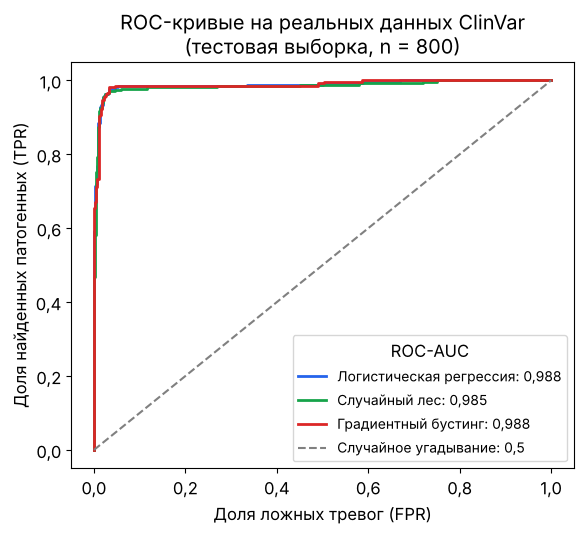

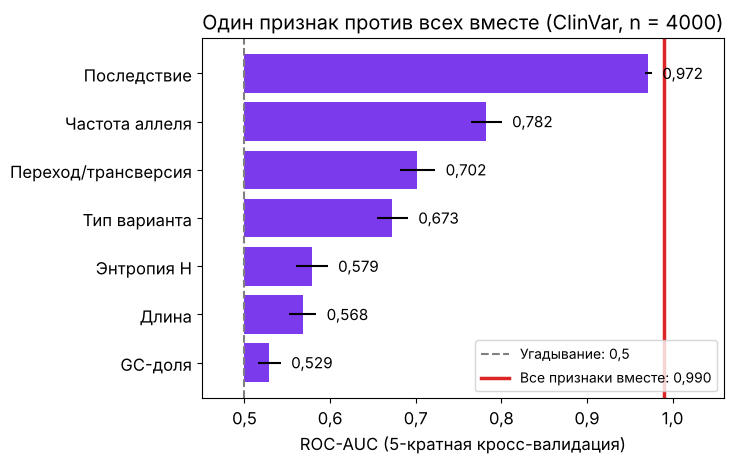

In [16]:
plt.rcParams.update({"font.size": 12, "axes.formatter.use_locale": False})
comma = lambda v: f"{v:.3f}".replace(".", ",")

fig, ax = plt.subplots(figsize=(6, 5.5))
for (name, pr), c in zip(probs.items(), ["#2563eb", "#16a34a", "#dc2626"]):
    fpr, tpr, _ = roc_curve(yte, pr)
    ax.step(fpr, tpr, where="post", color=c, lw=2, label=f"{name}: {comma(roc_auc_score(yte, pr))}")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Случайное угадывание: 0,5")
ax.set_xlabel("Доля ложных тревог (FPR)"); ax.set_ylabel("Доля найденных патогенных (TPR)")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.set_title("ROC-кривые на реальных данных ClinVar\n(тестовая выборка, n = 800)")
ax.legend(loc="lower right", fontsize=10, title="ROC-AUC")
fig.tight_layout(); fig.savefig("roc_clinvar.png", dpi=220, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
items = sorted(single.items(), key=lambda kv: kv[1].mean())
ax.barh([k for k, _ in items], [v.mean() - 0.5 for _, v in items], left=0.5,
        xerr=[v.std() for _, v in items], color="#7c3aed")
for i, (_, v) in enumerate(items):
    ax.text(v.mean() + v.std() + 0.012, i, comma(v.mean()), va="center", fontsize=11)
full = abl["Все признаки"].mean()
ax.axvline(0.5, color="gray", ls="--", label="Угадывание: 0,5")
ax.axvline(full, color="#dc2626", lw=2.5, label=f"Все признаки вместе: {comma(full)}")
ax.set_xlim(0.45, 1.06); ax.set_xlabel("ROC-AUC (5-кратная кросс-валидация)")
ax.set_title("Один признак против всех вместе (ClinVar, n = 4000)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.legend(loc="lower right", fontsize=10)
fig.tight_layout(); fig.savefig("single_feature_auc.png", dpi=220, bbox_inches="tight"); plt.show()

## Выводы этапа 2
1. Конвейер, построенный на синтетических данных, без изменений заработал на реальных вариантах ClinVar.
2. Все три модели дали ROC-AUC около 0,99 на тесте и в кросс-валидации, в том числе на генах, которых не было в обучении.
3. Гипотеза подтвердилась: все признаки вместе (0,990) лучше самого сильного одиночного признака — последствия мутации (0,972).
4. Энтропия Шеннона на реальных данных почти бесполезна (одна 0,58; без неё качество не меняется). Это честный отрицательный результат.
5. Среди миссенс-вариантов качество ниже (около 0,90), и его почти целиком даёт частота аллеля.

**Ограничения.** Эксперты ClinVar сами используют частоту аллеля и тип последствия при классификации (критерии ACMG),
поэтому высокий AUC частично отражает правила разметки, а не открытие новой биологии. Релиз 2019 года;
консервативность и биохимическая дистанция пока не посчитаны. Модель не предназначена для диагностики.